<a href="https://colab.research.google.com/github/nahsiz/99_days_of_coding_MLOps_With_CPC/blob/main/phase-1/day_18/day_18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Import Required Libraries

Text Box Title: Importing Required Libraries

Text Box Description: Import Pandas, NumPy, Matplotlib, and Seaborn for data analysis, correlation analysis, and data quality checks.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

2. Load the Dataset

Text Box Title: Loading the Diabetes Health Indicators Dataset

Text Box Description: Load the CSV file into a Pandas DataFrame and strip any extra whitespace from column names so all column names work correctly.

In [2]:
data = pd.read_csv('/content/diabetes_012_health_indicators_BRFSS2015.csv')
data.columns = data.columns.str.strip()

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


3. Display First 5 Rows

Text Box Title: Displaying the First 5 Rows

Text Box Description: Use the head() function to quickly verify the dataset was loaded correctly.

In [3]:
data.head()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


4. Dataset Shape and Information

Text Box Title: Checking Dataset Dimensions and Data Types

Text Box Description: Identify total rows and columns, then inspect column names, data types, and non-null counts using info().

In [4]:
print("Total Rows:", data.shape[0])
print("Total Columns:", data.shape[1])
print()
data.info()

Total Rows: 253680
Total Columns: 22

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth       

5. Check Missing Values

Text Box Title: Detecting Missing Values in Each Column

Text Box Description: Count missing values per column to identify any data quality issue before analysis.

In [5]:
missing = data.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if missing.empty:
    print("No missing values found in the dataset.")
else:
    print("Missing values per column:")
    print(missing)

No missing values found in the dataset.


6. Check Duplicate Rows

Text Box Title: Detecting Duplicate Rows

Text Box Description: Count duplicate rows in the dataset to check whether duplicate records need to be handled before correlation analysis.

In [6]:
duplicate_count = data.duplicated().sum()

print("Total duplicate rows:", duplicate_count)
print("Duplicate percentage:", round((duplicate_count / len(data)) * 100, 2), "%")

Total duplicate rows: 23899
Duplicate percentage: 9.42 %


7. Check Outliers (IQR Method on BMI)

Text Box Title: Detecting Outliers in the BMI Column

Text Box Description: Use the IQR method to count outliers in the BMI column, since BMI is our shared x-axis and outliers can distort the scatter plots and correlation values.

In [7]:
Q1 = data['BMI'].quantile(0.25)
Q3 = data['BMI'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = data[(data['BMI'] < lower_bound) | (data['BMI'] > upper_bound)]

print("Q1:", Q1, "| Q3:", Q3, "| IQR:", IQR)
print("Lower bound:", lower_bound, "| Upper bound:", upper_bound)
print("Number of BMI outliers:", len(outliers))
print("Outlier percentage:", round((len(outliers) / len(data)) * 100, 2), "%")

Q1: 24.0 | Q3: 31.0 | IQR: 7.0
Lower bound: 13.5 | Upper bound: 41.5
Number of BMI outliers: 9847
Outlier percentage: 3.88 %


8. Select Four Columns (Shared X-Axis)

Text Box Title: Selecting Four Columns for Correlation Analysis

Text Box Description: Select one shared x-axis column (BMI) and three y-axis columns (Diabetes_012, GenHlth, Age). BMI will stay on the x-axis in all scatter plots so the three relationships can be compared against the same horizontal axis.

In [8]:
x_col = 'BMI'
y_col_1 = 'Diabetes_012'
y_col_2 = 'GenHlth'
y_col_3 = 'Age'

selected_data = data[[x_col, y_col_1, y_col_2, y_col_3]]

selected_data.head()

,BMI,Diabetes_012,GenHlth,Age
0,40.0,0.0,5.0,9.0
1,25.0,0.0,3.0,7.0
2,28.0,0.0,5.0,9.0
3,27.0,0.0,2.0,11.0
4,24.0,0.0,2.0,11.0


9. Calculate Pearson Correlation

Text Box Title: Calculating Correlation Between Four Columns

Text Box Description: Calculate the Pearson correlation coefficient three times — BMI vs Diabetes_012, BMI vs GenHlth, and BMI vs Age. BMI remains the shared x-axis column in all three calculations.

In [9]:
correlation_1 = selected_data[x_col].corr(selected_data[y_col_1])
correlation_2 = selected_data[x_col].corr(selected_data[y_col_2])
correlation_3 = selected_data[x_col].corr(selected_data[y_col_3])

print("Correlation between", x_col, "and", y_col_1)
print("Pearson Correlation Coefficient:", round(correlation_1, 4))
print()
print("Correlation between", x_col, "and", y_col_2)
print("Pearson Correlation Coefficient:", round(correlation_2, 4))
print()
print("Correlation between", x_col, "and", y_col_3)
print("Pearson Correlation Coefficient:", round(correlation_3, 4))

Correlation between BMI and Diabetes_012
Pearson Correlation Coefficient: 0.2244

Correlation between BMI and GenHlth
Pearson Correlation Coefficient: 0.2392

Correlation between BMI and Age
Pearson Correlation Coefficient: -0.0366


10. Correlation Heatmap (4×4)

Text Box Title: Visualizing Correlation Using a Heatmap

Text Box Description: Create a 4×4 heatmap to display the correlation coefficients between all four selected columns at a glance.

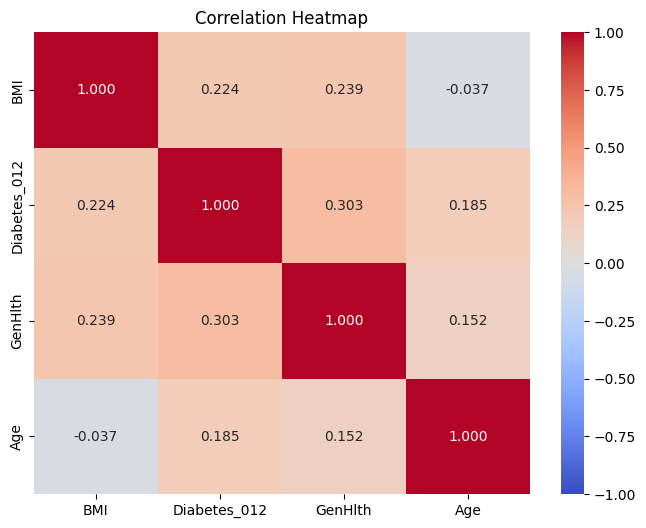

In [10]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    selected_data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.3f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap')
plt.show()

11. Scatter Plot — Shared X with First Y

Text Box Title: Visualizing BMI vs Diabetes_012

Text Box Description: Create a scatter plot with a regression line where BMI is on the x-axis and Diabetes_012 is on the y-axis. BMI stays on the x-axis because it is the shared axis for all three plots.

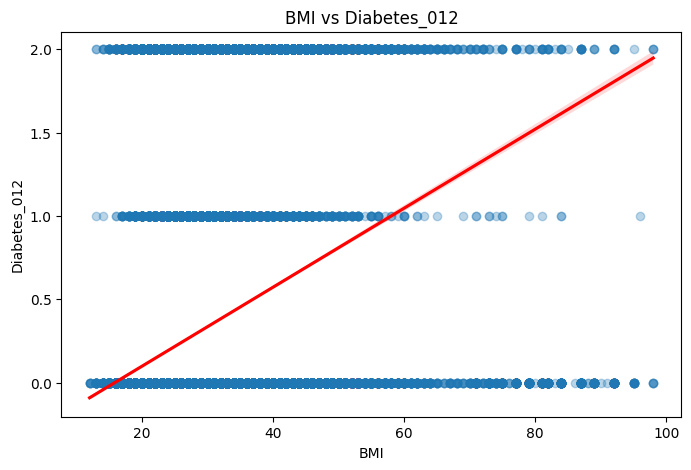

In [11]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=selected_data,
    x=x_col,
    y=y_col_1,
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'}
)

plt.title(f'{x_col} vs {y_col_1}')
plt.xlabel(x_col)
plt.ylabel(y_col_1)
plt.show()

12. Scatter Plot — Shared X with Second Y

Text Box Title: Visualizing BMI vs GenHlth

Text Box Description: Create a scatter plot with a regression line where BMI is again on the x-axis, but GenHlth is now on the y-axis. The x-axis stays identical to the previous plot so both relationships share the same horizontal axis.

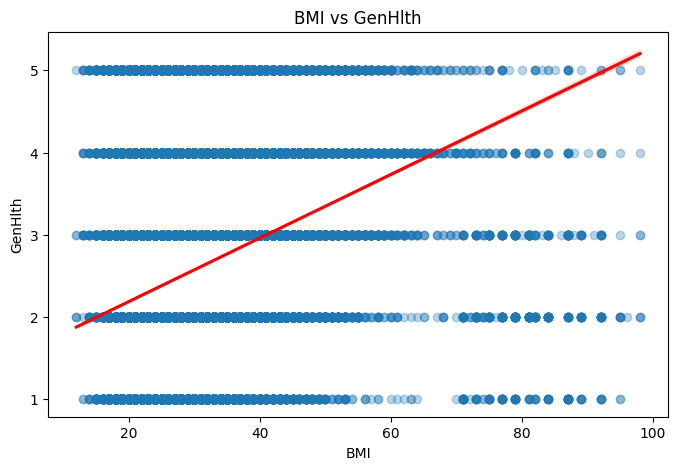

In [12]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=selected_data,
    x=x_col,
    y=y_col_2,
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'}
)

plt.title(f'{x_col} vs {y_col_2}')
plt.xlabel(x_col)
plt.ylabel(y_col_2)
plt.show()

13. Scatter Plot — Shared X with Third Y

Text Box Title: Visualizing BMI vs Age

Text Box Description: Create a scatter plot with a regression line where BMI is again on the x-axis, but Age is now on the y-axis. The x-axis stays identical so all three plots share the same horizontal axis.

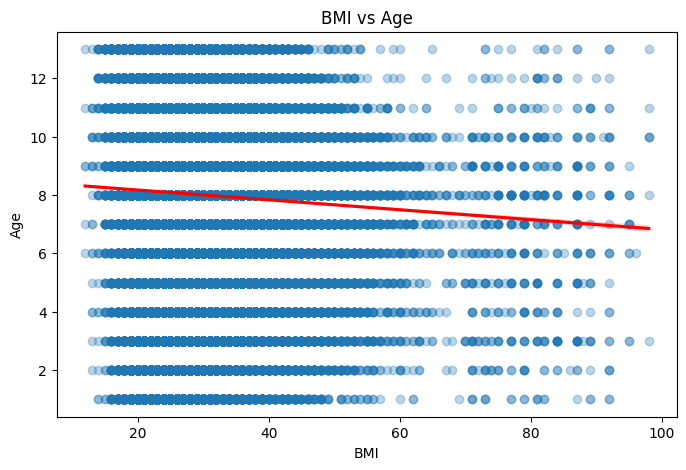

In [13]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=selected_data,
    x=x_col,
    y=y_col_3,
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'}
)

plt.title(f'{x_col} vs {y_col_3}')
plt.xlabel(x_col)
plt.ylabel(y_col_3)
plt.show()

14. Histograms — Check Skew and Spikes

Text Box Title: Visualizing Distributions to Detect Skew

Text Box Description: Plot histograms with KDE curves for all four selected columns side by side to detect which distributions are skewed, bimodal, or have odd spikes. This supports the histogram-based finding in NOTES.md.

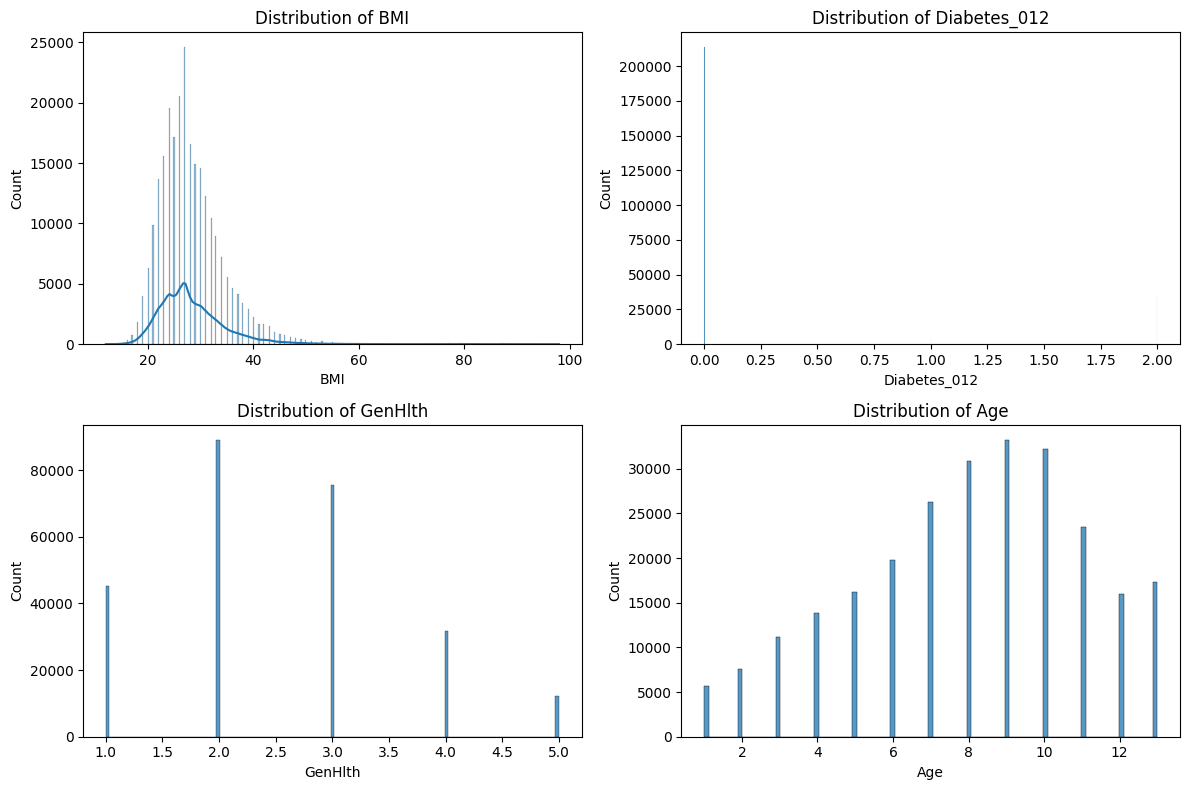

Skewness of BMI : 2.122
Skewness of Diabetes_012 : 1.9764
Skewness of GenHlth : 0.4229
Skewness of Age : -0.3599


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(data[x_col], kde=True, ax=axes[0, 0])
axes[0, 0].set_title(f'Distribution of {x_col}')

sns.histplot(data[y_col_1], kde=False, ax=axes[0, 1])
axes[0, 1].set_title(f'Distribution of {y_col_1}')

sns.histplot(data[y_col_2], kde=False, ax=axes[1, 0])
axes[1, 0].set_title(f'Distribution of {y_col_2}')

sns.histplot(data[y_col_3], kde=False, ax=axes[1, 1])
axes[1, 1].set_title(f'Distribution of {y_col_3}')

plt.tight_layout()
plt.show()

print("Skewness of", x_col, ":", round(data[x_col].skew(), 4))
print("Skewness of", y_col_1, ":", round(data[y_col_1].skew(), 4))
print("Skewness of", y_col_2, ":", round(data[y_col_2].skew(), 4))
print("Skewness of", y_col_3, ":", round(data[y_col_3].skew(), 4))

15. Interpret the Correlation Results

Text Box Title: Interpreting All Three Correlation Coefficients

Text Box Description: Identify whether each relationship between BMI and the three y-columns is positive, negative, or has no linear correlation.

In [15]:
for label, value in [(y_col_1, correlation_1),
                     (y_col_2, correlation_2),
                     (y_col_3, correlation_3)]:
    print(f"{x_col} vs {label}")
    if value > 0:
        print("  Positive Correlation")
    elif value < 0:
        print("  Negative Correlation")
    else:
        print("  No Linear Correlation")
    print("  Correlation Value:", round(value, 4))
    print()

BMI vs Diabetes_012
  Positive Correlation
  Correlation Value: 0.2244

BMI vs GenHlth
  Positive Correlation
  Correlation Value: 0.2392

BMI vs Age
  Negative Correlation
  Correlation Value: -0.0366



16. Display Final Correlation Result

Text Box Title: Final Correlation Analysis Result

Text Box Description: Display the shared x-axis column name and all three y-axis column names along with their calculated Pearson correlation coefficients.

In [16]:
print("Final Correlation Analysis")
print("--------------------------")

print("Shared X-Axis Column :", x_col)
print("First Y-Axis Column  :", y_col_1)
print("Pearson Correlation  :", round(correlation_1, 4))
print()

print("Shared X-Axis Column :", x_col)
print("Second Y-Axis Column :", y_col_2)
print("Pearson Correlation  :", round(correlation_2, 4))
print()

print("Shared X-Axis Column :", x_col)
print("Third Y-Axis Column  :", y_col_3)
print("Pearson Correlation  :", round(correlation_3, 4))

Final Correlation Analysis
--------------------------
Shared X-Axis Column : BMI
First Y-Axis Column  : Diabetes_012
Pearson Correlation  : 0.2244

Shared X-Axis Column : BMI
Second Y-Axis Column : GenHlth
Pearson Correlation  : 0.2392

Shared X-Axis Column : BMI
Third Y-Axis Column  : Age
Pearson Correlation  : -0.0366
